In [178]:
""" The goal of this notebook is to setp by step develop Metadynamics code for ASE.
    It will be based on the biASE calculator
""" 

' The goal of this notebook is to setp by step develop Metadynamics code for ASE.\n    It will be based on the biASE calculator\n'

In [179]:
from biASE import General_Bias_Calculator

In [180]:
from ase.atoms import Atoms
from ase import units
from ase.io import read


from ase.md.langevin import Langevin
from ase.md.verlet import VelocityVerlet
from ase.md.velocitydistribution import MaxwellBoltzmannDistribution,Stationary, ZeroRotation
from ase.constraints import FixedPlane


import numpy as np
import matplotlib.pyplot as plt
from ase.calculators.calculator import Calculator, all_changes

from ase.constraints import FixedPlane
from ase.io import Trajectory
import copy

from ase.calculators.mixing import LinearCombinationCalculator
import time
import jax.numpy as jnp
from jax import jit
from jax import grad ,jacfwd,jacrev

In [181]:
class Metadynamics(Langevin):
    """
    
    """
    ### list of suported thermostats 
    thermostats=['Langevin'] 

In [201]:
"""Langevin dynamics class.""" #copyed from the v3.22.1 not the master!

import numpy as np

from ase.md.md import MolecularDynamics
from ase.parallel import world, DummyMPI
from ase import units


class Metadynamics(MolecularDynamics):
    """Langevin (constant N, V, T) molecular dynamics."""

    # Helps Asap doing the right thing.  Increment when changing stuff:
    _lgv_version = 4

    def __init__(self, atoms, timestep, temperature=None, friction=None,
                 fixcm=True, *, temperature_K=None, trajectory=None,
                 logfile=None, loginterval=1, communicator=world,
                 rng=None, append_trajectory=False,meta_dyn=True,cvs = None,std_dev=0.1,bias_height = 0.001, interval_size = 10):
        """
        Parameters:

        atoms: Atoms object
            The list of atoms.

        timestep: float
            The time step in ASE time units.

        temperature: float (deprecated)
            The desired temperature, in electron volt.

        temperature_K: float
            The desired temperature, in Kelvin.

        friction: float
            A friction coefficient, typically 1e-4 to 1e-2.

        fixcm: bool (optional)
            If True, the position and momentum of the center of mass is
            kept unperturbed.  Default: True.

        rng: RNG object (optional)
            Random number generator, by default numpy.random.  Must have a
            standard_normal method matching the signature of
            numpy.random.standard_normal.

        logfile: file object or str (optional)
            If *logfile* is a string, a file with that name will be opened.
            Use '-' for stdout.

        trajectory: Trajectory object or str (optional)
            Attach trajectory object.  If *trajectory* is a string a
            Trajectory will be constructed.  Use *None* (the default) for no
            trajectory.

        communicator: MPI communicator (optional)
            Communicator used to distribute random numbers to all tasks.
            Default: ase.parallel.world. Set to None to disable communication.

        append_trajectory: bool (optional)
            Defaults to False, which causes the trajectory file to be
            overwritten each time the dynamics is restarted from scratch.
            If True, the new structures are appended to the trajectory
            file instead.

        The temperature and friction are normally scalars, but in principle one
        quantity per atom could be specified by giving an array.

        RATTLE constraints can be used with these propagators, see:
        E. V.-Eijnden, and G. Ciccotti, Chem. Phys. Lett. 429, 310 (2006)

        The propagator is Equation 23 (Eq. 39 if RATTLE constraints are used)
        of the above reference.  That reference also contains another
        propagator in Eq. 21/34; but that propagator is not quasi-symplectic
        and gives a systematic offset in the temperature at large time steps.
        """
        if friction is None:
            raise TypeError("Missing 'friction' argument.")
        self.fr = friction
        self.temp = units.kB * self._process_temperature(temperature,
                                                         temperature_K, 'eV')
        self.fix_com = fixcm
        if communicator is None:
            communicator = DummyMPI()
        self.communicator = communicator
        if rng is None:
            self.rng = np.random
        else:
            self.rng = rng
        MolecularDynamics.__init__(self, atoms, timestep, trajectory,
                                   logfile, loginterval,
                                   append_trajectory=append_trajectory)
        self.updatevars()
        
        ### Added from med
        self.position_array= None
        print("Initial Array:",self.position_array, atoms.get_positions().shape)
        self.meta_dyn = meta_dyn
        if meta_dyn ==True and cvs==None:
             raise TypeError("Please provide cvs  if you want to use the Metadynamics option (meta_dyn)!")
        else:
            self.cvs = cvs
            self.len_cvs = len(list(self.cvs(atoms.get_positions())))
        self.std_dev =std_dev
        self.main_potential = atoms.get_calculator()
        self.bias_height= bias_height
        self.interval_size = interval_size
        
    def todict(self):
        d = MolecularDynamics.todict(self)
        d.update({'temperature_K': self.temp / units.kB,
                  'friction': self.fr,
                  'fixcm': self.fix_com})
        return d

    def set_temperature(self, temperature=None, temperature_K=None):
        self.temp = units.kB * self._process_temperature(temperature,
                                                         temperature_K, 'eV')
        self.updatevars()

    def set_friction(self, friction):
        self.fr = friction
        self.updatevars()

    def set_timestep(self, timestep):
        self.dt = timestep
        self.updatevars()

    def updatevars(self):
        dt = self.dt
        T = self.temp
        fr = self.fr
        masses = self.masses
        sigma = np.sqrt(2 * T * fr / masses)

        self.c1 = dt / 2. - dt * dt * fr / 8.
        self.c2 = dt * fr / 2 - dt * dt * fr * fr / 8.
        self.c3 = np.sqrt(dt) * sigma / 2. - dt**1.5 * fr * sigma / 8.
        self.c5 = dt**1.5 * sigma / (2 * np.sqrt(3))
        self.c4 = fr / 2. * self.c5

    def step(self, forces=None):
        atoms = self.atoms
        natoms = len(atoms)

        if forces is None:
            forces = atoms.get_forces(md=True)

        # This velocity as well as xi, eta and a few other variables are stored
        # as attributes, so Asap can do its magic when atoms migrate between
        # processors.
        self.v = atoms.get_velocities()

        self.xi = self.rng.standard_normal(size=(natoms, 3))
        self.eta = self.rng.standard_normal(size=(natoms, 3))

        # When holonomic constraints for rigid linear triatomic molecules are
        # present, ask the constraints to redistribute xi and eta within each
        # triple defined in the constraints. This is needed to achieve the
        # correct target temperature.
        for constraint in self.atoms.constraints:
            if hasattr(constraint, 'redistribute_forces_md'):
                constraint.redistribute_forces_md(atoms, self.xi, rand=True)
                constraint.redistribute_forces_md(atoms, self.eta, rand=True)

        self.communicator.broadcast(self.xi, 0)
        self.communicator.broadcast(self.eta, 0)

        # First halfstep in the velocity.
        self.v += (self.c1 * forces / self.masses - self.c2 * self.v +
                   self.c3 * self.xi - self.c4 * self.eta)

        # Full step in positions
        x = atoms.get_positions()
        if self.fix_com:
            old_com = atoms.get_center_of_mass()
        # Step: x^n -> x^(n+1) - this applies constraints if any.
        atoms.set_positions(x + self.dt * self.v + self.c5 * self.eta)
        if self.fix_com:
            atoms.set_center_of_mass(old_com)

        # recalc velocities after RATTLE constraints are applied
        self.v = (self.atoms.get_positions() - x -
                  self.c5 * self.eta) / self.dt
        forces = atoms.get_forces(md=True)

        # Update the velocities
        self.v += (self.c1 * forces / self.masses - self.c2 * self.v +
                   self.c3 * self.xi - self.c4 * self.eta)

        if self.fix_com:  # subtract center of mass vel
            self.v -= self._get_com_velocity(self.v)

        # Second part of RATTLE taken care of here
        atoms.set_momenta(self.v * self.masses)
        start = time.time()
        ### We update here the potenial if wanted!
        if self.nsteps % self.interval_size ==0:
            if self.meta_dyn == True:
                if self.position_array is None:
                    self.position_array = np.array([self.cvs(atoms.get_positions())]) # save only cv instead of position!!!
                    print(self.position_array)
                else:
                    #print("Old Means: ",self.position_array, " New Mean: ", self.cvs(atoms.get_positions()))
                    self.position_array = np.vstack([self.position_array, self.cvs(atoms.get_positions())]) # save only cv instead of position!!!
                    #print(self.position_array)


                self.bias_potential = self.bias_setup(atoms, self.position_array,self.cvs)
                #print(self.position_array)
                self.meta_dyn_calc = LinearCombinationCalculator([self.main_potential,self.bias_potential],[1.,1.])
                atoms.calc =self.meta_dyn_calc
                end = time.time()
                #print(end-start)
                #print(self.nsteps)
        return forces

    def bias_setup(self,atoms, bias_positions,cvs):
        """Here the bias along the cv will be build
           ATM only one cvs with a one dimensional gaussian will be supported
        
        """
        if self.len_cvs ==1:
            self.gauissian_bias = General_Bias_Calculator(cvs,self.gaussian_1D,use_jit=True)
        elif self.len_cvs ==2:
            self.gauissian_bias = General_Bias_Calculator(cvs,self.gaussian_2D,use_jit=True)
        else:
            raise TypeError("CVs need to be inform of an array with one or two entrys! e.g. jnp.array([cv1,cv2]).")
            
        return self.gauissian_bias
    

    def gaussian_1D(self,cvs): ### here with jax numpy
        """ 
        x (float or numpy array): Input value(s) for evaluating the Gaussian.
            mean (float or numpy array): Mean(s) of the Gaussian(s).
            std_dev (float): Standard deviation of the Gaussian(s).

        Returns:
            float or numpy array: Value(s) of the Gaussian(s) at the given input(s), summed over all means.
            
            
            this function needs to be tested! seems to be the same as the above numpy version but forces need to be tested
        """ 
        x = cvs[0]
        mean_cvs = self.position_array.flatten()
        std_dev = self.std_dev

        # Evaluate the Gaussian for all means at once using numpy broadcasting
        gaussian_vals = jnp.exp(-0.5*((x - mean_cvs[:, jnp.newaxis])**2/(0.5*std_dev**2))) 
        
        # Sum over all means and return the result
        #print(jnp.sum(gaussian_vals, axis=0)[0])
        return self.bias_height*jnp.sum(gaussian_vals, axis=0)[0] # why [0] check that more - is necessay bc out put would be a 1D list with one entrence
    
    
    def gaussian_2D(self,cvs):
        """
        Evaluate a 2D Gaussian potential energy surface for the given input collective variable(s) (cvs).

        Args:
            cvs (float or numpy array): Input value(s) for evaluating the 2D Gaussian.

        Returns:
            float or numpy array: Value(s) of the 2D Gaussian at the given input(s), summed over all means.
        """
        x, y = cvs
        mean_cvs= self.position_array
        std_dev = self.std_dev
        
        #print(mean_cvs[:, 0])
        # Evaluate the Gaussian for all means at once using numpy broadcasting
        gaussian_vals = jnp.exp(-0.5*((x - mean_cvs[:, 0])**2/(0.5*std_dev**2)) \
                                                      - 0.5*((y - mean_cvs[:, 1])**2/(0.5*std_dev**2)))

        # Sum over all means and return the result
        #print(jnp.sum(gaussian_vals, axis=0)[0])
        return self.bias_height*jnp.sum(gaussian_vals,axis=0)#[0] 


    def return_bias(self):
        return self.bias_potential
    
    def return_biased_potential(self):
        return self.meta_dyn_calc

In [183]:
def plot_2d_bias(f_bias,rangeCV1=[-1,1],rangeCV2=[-1,1],N_points=100,trajectory=None):
    x = np.linspace(rangeCV1[0], rangeCV1[1], N_points)
    y = np.linspace(rangeCV2[0], rangeCV2[1], N_points)

    X, Y = np.meshgrid(x, y)
    CVs=[X,Y]
    Z = f_bias(CVs)
    
    plt.contour(X, Y, Z, 50, cmap='RdGy')
    plt.colorbar()
    
    if trajectory==None:
        plt.show()
    else:
        plt.plot(trajectory[0],trajectory[1])
        plt.xlabel('x')
        plt.ylabel('y')
        plt.savefig('2D_plot.png')
        plt.show()

def plot_1d_bias(f_bias,rangeCV1=[-0.1,1.5],N_points=100,trajectory=None,pic_name = '1D_DW_C.png'):
    x = np.linspace(rangeCV1[0], rangeCV1[1], N_points)
    
    try:
        CVs=[x] #needs to be an array for the spring method
        Z = f_bias(CVs)
        plt.plot(x, Z)
    except:
        CVs=np.array(x) #needs to be an array for the spring method
        Z = f_bias(CVs)
        plt.plot(x, Z)
    if trajectory==None:
        plt.show()
    else:
        plt.hist(trajectory[0],density=True,bins=100,range=rangeCV1)
        plt.xlabel('x')
        plt.ylabel('E')
        plt.savefig(pic_name)
        plt.show()
        

        

In [184]:
def _cvs(atom_pos):
    '''Collective variable from the x cooridinate'''
    x = atom_pos[0][0]
    return jnp.array([x])

def _cvs_2D(atom_pos):
    '''Collective variable from the x and y cooridinate'''
    x = atom_pos[0][0]
    y = atom_pos[0][1]
    return jnp.array([x,y])
"""
def _cvs(atom_pos):
    '''Collective variable from the x, y and z cooridinate'''
    x = atom_pos[0][0]
    y = atom_pos[0][1]
    z = atom_pos[0][2]
    return jnp.array([x,y,z])"""

def f_dw_cvs(cvs,scale=0.2):
    '''Double-Well'''
    x =  cvs[0]
    y =  cvs[1]
    return scale*((x**2 - 1)**2 + y**2)

def f_cvs(cvs,scale=.04):
    x = cvs[0]
    y = cvs[1]
    r = jnp.sqrt(x**2 + y**2)
    large_min = jnp.exp(-0.5*((r)/0.5)**2)
    small_mins = 0
    for i in range(5):
        x0 = 1*jnp.cos(2*jnp.pi*i/5)
        y0 = 1*jnp.sin(2*jnp.pi*i/5)
        small_mins += 1*jnp.exp(-0.5*((x-x0)**2 + (y-y0)**2)/0.2**2)

        x1 = 1.5*jnp.cos(2*jnp.pi*i/5 + jnp.pi/5)
        y1 = 1.5*jnp.sin(2*jnp.pi*i/5 + jnp.pi/5)
        small_mins += 0.8*jnp.exp(-0.2*((x-x1)**2 + (y-y1)**2)/0.2**2)

        x2=4.5*jnp.cos(2*jnp.pi*i/5 + jnp.pi/(2.5))
        y2= 4.5*jnp.sin(2*jnp.pi*i/5 + jnp.pi/(2.5))
        small_mins += 1*jnp.exp(-0.1*((x-x2)**2 + (y-y2)**2)/0.2**2)

    return scale*(-10*large_min - 10*small_mins + (x**2 +y**2))

def f_cvs_1D(cvs):
    x = cvs[0]
    return x**2*(1.-x)**2

def deriv_f_cvs_1D(cvs):
    x = cvs[0]
    df_dx = 2*x*(1.-x)*(2*x-1.)
    return np.array([[df_dx,0,0]])

def deriv_f_cvs_1D(cvs, h=1e-4):
    f0 = f_cvs_1D(cvs)
    x = cvs[0]
    fx = f_cvs_1D([x+h])
    fd = (fx - f0) / h
    return np.array([[fd,0,0]])

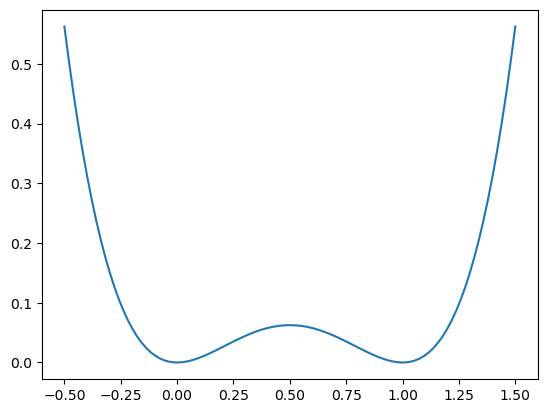

In [185]:
plot_1d_bias(f_cvs_1D,trajectory=None,rangeCV1=[-0.5,1.5])

[[ 0.0407239  -0.06027824 -0.03848015]]
10001


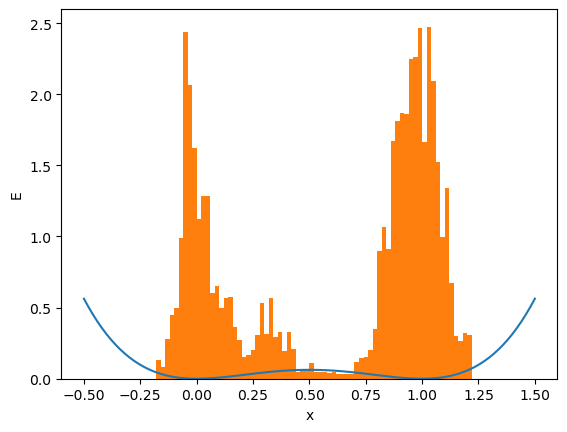

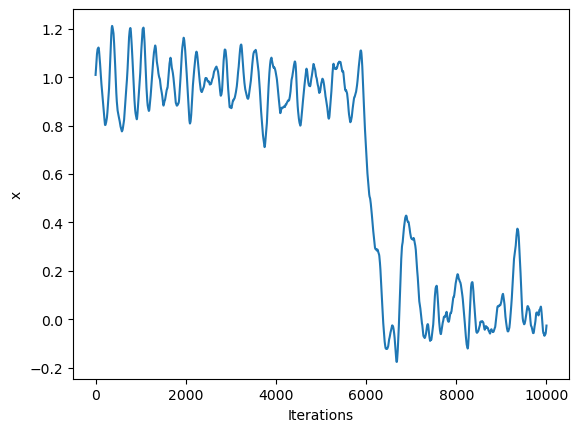

In [189]:
atoms = Atoms('C',[[1.01,0.0,0.0]])
jax_calc = General_Bias_Calculator(_cvs,f_cvs_1D)
atoms.calc = jax_calc 


MaxwellBoltzmannDistribution(atoms, temperature_K=600)
''' the first calc is thrash then but the second one looks great???
Stationary(atoms)  # zero linear momentum
ZeroRotation(atoms)  # zero angular momentum'''
print(atoms.get_velocities())
dyn = Langevin(atoms, timestep=.5 * units.fs, temperature_K=300, friction=0.1, trajectory='md.traj',fixcm=False)#Andersen(atoms, timestep=.5 * units.fs, temperature_K=3000, andersen_prob=0.01,trajectory='md.traj')#

#dyn = VelocityVerlet(atoms, timestep=1.0 * units.fs, trajectory='md.traj')

N_steps = int(1e4)
dyn.run(N_steps) 

traj = read('md.traj@::1')
print(len(traj))

#print(traj)
#print()
x = []
y = np.zeros(N_steps+1)
z = np.zeros(N_steps+1)

# Define an array to store the temperature at each step
temperatures = np.zeros(N_steps+1)
# Define an array to store the energy at each step
energy = np.zeros(N_steps+1)
kin = np.zeros(N_steps+1)
pot = np.zeros(N_steps+1)

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    x.append(xyz[0][0])
    y[i] = xyz[0][1]
    z[i] = xyz[0][2]
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    '''pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()'''
    
    
plot_1d_bias(f_cvs_1D,trajectory=[x],rangeCV1=[-0.5,1.5])

plt.xlabel('Iterations')
plt.ylabel('x')

plt.plot(x)
#plt.plot(y)
#plt.plot(z)
plt.savefig('X_movement_DW_C.png')

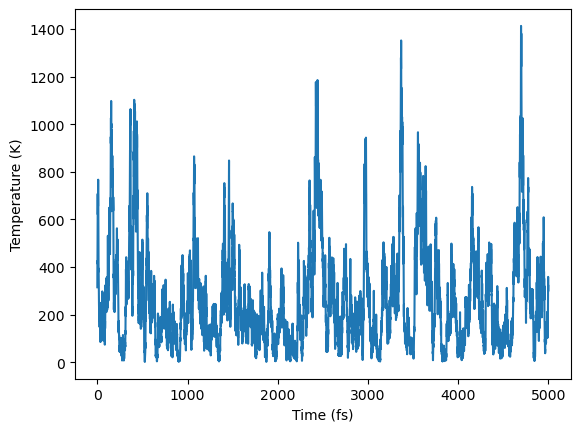

262.62131249959094


In [190]:
# Plot the temperature as a function of time
timestep = .5*units.fs
time_ = np.arange(N_steps+1) * timestep / units.fs
plt.plot(time_, temperatures)#/ units.kB)
plt.xlabel('Time (fs)')
plt.ylabel('Temperature (K)')
plt.savefig('NVT_DW_temp.png')
plt.show()
print(np.average(np.array(temperatures)))

[[ 0.06025193 -0.01398635 -0.09028384]]
Initial Array: None (1, 3)
[[1.0130446]]
10001


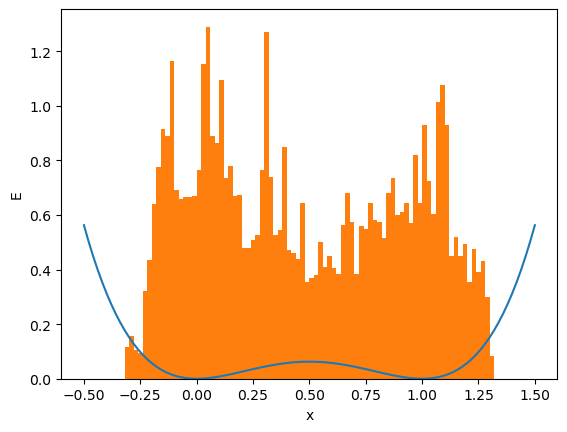

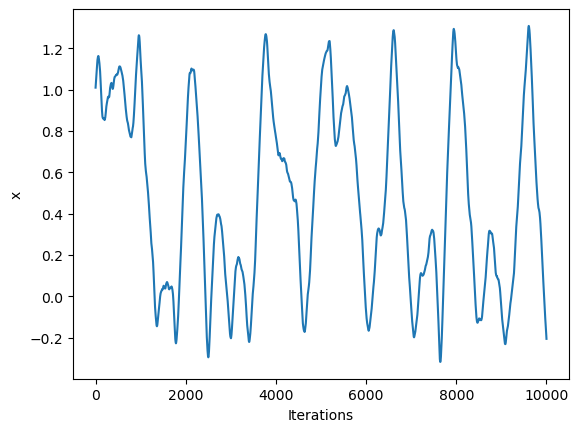

In [191]:
atoms = Atoms('C',[[1.01,0.0,0.0]])
jax_calc = General_Bias_Calculator(_cvs,f_cvs_1D)
atoms.calc = jax_calc 


MaxwellBoltzmannDistribution(atoms, temperature_K=600)
''' the first calc is thrash then but the second one looks great???
Stationary(atoms)  # zero linear momentum
ZeroRotation(atoms)  # zero angular momentum'''
print(atoms.get_velocities())
dyn = Metadynamics(atoms, timestep=.5 * units.fs, temperature_K=300, friction=0.1, trajectory='md.traj',fixcm=False,cvs=_cvs,interval_size=10)#Andersen(atoms, timestep=.5 * units.fs, temperature_K=3000, andersen_prob=0.01,trajectory='md.traj')#

#dyn = VelocityVerlet(atoms, timestep=1.0 * units.fs, trajectory='md.traj')

N_steps = int(1e4)
dyn.run(N_steps) 

traj = read('md.traj@::1')
print(len(traj))

#print(traj)
#print()
x = []
y = np.zeros(N_steps+1)
z = np.zeros(N_steps+1)

# Define an array to store the temperature at each step
temperatures = np.zeros(N_steps+1)
# Define an array to store the energy at each step
energy = np.zeros(N_steps+1)
kin = np.zeros(N_steps+1)
pot = np.zeros(N_steps+1)

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    x.append(xyz[0][0])
    y[i] = xyz[0][1]
    z[i] = xyz[0][2]
    
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    '''pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()'''
    
    
plot_1d_bias(f_cvs_1D,trajectory=[x],rangeCV1=[-0.5,1.5], pic_name = 'Meta_dyn_1D_DW.png')

plt.xlabel('Iterations')
plt.ylabel('x')
plt.plot(x)
#plt.plot(y)
#plt.plot(z)
#plt.savefig('X_movement_DW_C.png')

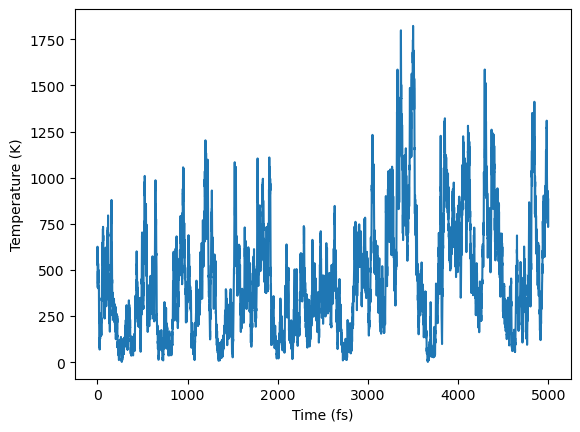

451.9698234088538


In [192]:
# Plot the temperature as a function of time
timestep = .5*units.fs
time_ = np.arange(N_steps+1) * timestep / units.fs
plt.plot(time_, temperatures)#/ units.kB)
plt.xlabel('Time (fs)')
plt.ylabel('Temperature (K)')
plt.savefig('NVT_DW_temp.png')
plt.show()
print(np.average(np.array(temperatures)))

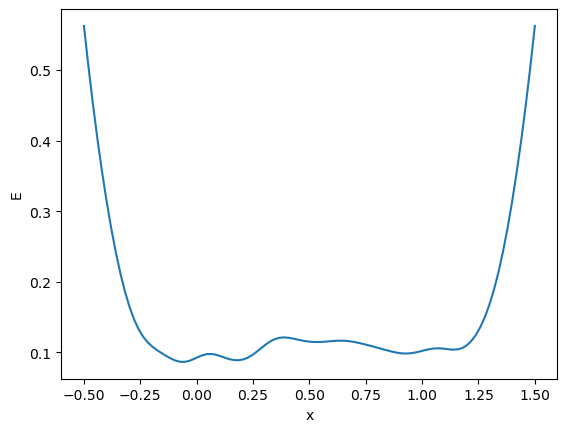

In [193]:
# Here now the biased potential should be plotted

atoms = Atoms('C',[[0.0,0.0,0.0]])



Z=[]
x = np.linspace(-0.5, 1.5, 100)

for i in x:
    atoms1=copy.deepcopy(atoms)
    pos = atoms.get_positions()
    pos[0][0]+=i
    atoms1.calc = dyn.return_biased_potential()
    atoms1.set_positions(pos)
     #needs to be an array for the spring method
    Z.append(atoms1.get_potential_energy())
plt.plot(x, Z)
plt.xlabel('x')
plt.ylabel('E')
plt.savefig('biased_1D_DW_C.png')
plt.show()

In [194]:
import random
jax_calc = General_Bias_Calculator(_cvs,f_cvs_1D)
atoms.calc = jax_calc 
pos = atoms.get_positions()

In [195]:
%%timeit -r 5 -n 1000 
pos[0][0]+= random.uniform(0.01, 0.1)
atoms.set_positions(pos)
atoms.get_forces()

259 µs ± 12 µs per loop (mean ± std. dev. of 5 runs, 1,000 loops each)


In [196]:
atoms1.calc = dyn.return_biased_potential()

In [197]:
%%timeit -r 5 -n 1000 
pos[0][0]+= random.uniform(0.01, 0.1)
atoms1.set_positions(pos)
atoms1.get_forces()

412 µs ± 9.74 µs per loop (mean ± std. dev. of 5 runs, 1,000 loops each)


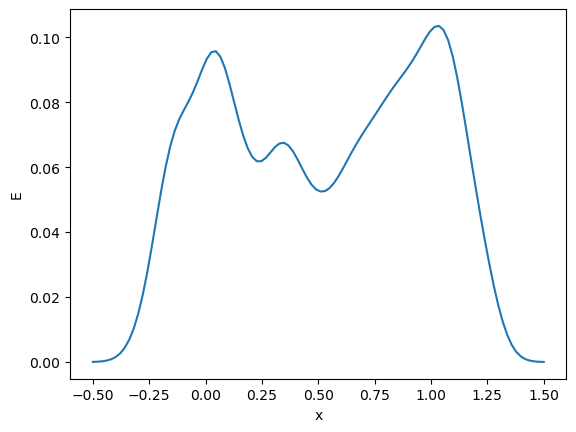

In [198]:
# Here now the biased potential should be plotted

atoms = Atoms('C',[[0.0,0.0,0.0]])



Z=[]
x = np.linspace(-0.5, 1.5, 100)

for i in x:
    atoms1=copy.deepcopy(atoms)
    pos = atoms.get_positions()
    pos[0][0]+=i
    atoms1.calc = dyn.return_bias()
    atoms1.set_positions(pos)
     #needs to be an array for the spring method
    Z.append(atoms1.get_potential_energy())
plt.plot(x, Z)
plt.xlabel('x')
plt.ylabel('E')
plt.savefig('bias_1D_DW_C.png')
plt.show()

In [ ]:
import numpy as np
import jax.numpy as jnp
from jax import jit
import matplotlib.pyplot as plt

# Define the Gaussian function using numpy
def gaussian_np(x, mean, std_dev):
    """
        x (float or numpy array): Input value(s) for evaluating the Gaussian.
        mean (float or numpy array): Mean(s) of the Gaussian(s).
        std_dev (float): Standard deviation of the Gaussian(s).

    Returns:
        float or numpy array: Value(s) of the Gaussian(s) at the given input(s), summed over all means.

        this function needs to be tested!
    """
    # Ensure that mean is a 1D numpy array
    mean = np.atleast_1d(mean)

    # Evaluate the Gaussian for all means at once using numpy broadcasting
    gaussian_vals = np.exp(-0.5*((x - mean[:, jnp.newaxis])**2/(0.5*std_dev**2)))  #/ (std_dev * np.sqrt(2 * np.pi))

    # Sum over all means and return the result
    return np.sum(gaussian_vals, axis=0)
# Define the Gaussian function using JAX numpy
@jit
def gaussian_jax(x, mean, std_dev):
    
    """
        x (float or numpy array): Input value(s) for evaluating the Gaussian.
        mean (float or numpy array): Mean(s) of the Gaussian(s).
        std_dev (float): Standard deviation of the Gaussian(s).

    Returns:
        float or numpy array: Value(s) of the Gaussian(s) at the given input(s), summed over all means.


        this function needs to be tested!
    """
    # Ensure that mean is a 1D numpy array
    mean = jnp.atleast_1d(mean)

    # Evaluate the Gaussian for all means at once using numpy broadcasting
    gaussian_vals = jnp.exp(-0.5*((x - mean[:, jnp.newaxis])**2/(0.5*std_dev**2))) 

    # Sum over all means and return the result
    print(jnp.sum(gaussian_vals, axis=0))
    return jnp.sum(gaussian_vals, axis=0)

# Define the means and standard deviations to use
means = np.array([-2, -1, 0, 1, 2])
sigmas = np.array([0.5, 1, 2])

# Generate x values to evaluate the Gaussian functions at
x = np.linspace(-5, 5, 500)

# Evaluate the Gaussian functions at each set of means and standard deviations
gaussians_np = np.zeros((len(sigmas), len(means), len(x)))
for i, sigma in enumerate(sigmas):
    for j, mean in enumerate(means):
        gaussians_np[i, j] = gaussian_np(x, mean, sigma)

gaussians_jax = np.zeros((len(sigmas), len(means), len(x)))
for i, sigma in enumerate(sigmas):
    for j, mean in enumerate(means):
        gaussians_jax[i, j] = np.asarray(gaussian_jax(x, mean, sigma))

# Plot the Gaussian functions
for i, sigma in enumerate(sigmas):
    for j, mean in enumerate(means):
        plt.plot(x, gaussians_np[i, j], label=f"Mean = {mean}")
    plt.title(f"Gaussian Functions with Std Dev = {sigma}")
    plt.legend()
    plt.show()
    for j, mean in enumerate(means):
        plt.plot(x, gaussians_jax[i, j], label=f"Mean = {mean}")
    plt.title(f"Gaussian Functions with Std Dev = {sigma} from the Jax code")
    plt.legend()
    plt.show()

    
# Plot the Gaussian functions
for i, sigma in enumerate(sigmas):
    for j, mean in enumerate(means):
        plt.plot(x, gaussians_np[i, j], label=f"Mean = {mean}")
        plt.plot(x, gaussians_jax[i, j], label=f"Mean_jax = {mean}")
    plt.title(f"Gaussian Functions with Std Dev = {sigma}")
    plt.legend()
    plt.show()

       



In [ ]:
import jax.numpy as jnp
from jax import jit
import matplotlib.pyplot as plt

# Define the Gaussian function using JAX
@jit
def gaussian_jax(x, mean, std_dev):
    mean = jnp.atleast_1d(mean)
    gaussian_vals = jnp.exp(-0.5*((x - mean[:, jnp.newaxis])**2/(0.5*std_dev**2)))
    return jnp.sum(gaussian_vals, axis=0)

# Define the inputs
x = jnp.linspace(-5, 5, 1000)
means = jnp.array([-2, -1, 0, 1, 2])
std_dev = 1

# Compute the sum of all 5 Gaussians
gaussian_sum = gaussian_jax(x, means, std_dev)

# Plot the result
plt.plot(x, gaussian_sum)
plt.xlabel('x')
plt.ylabel('Gaussian sum')
plt.show()


In [21]:
#checks is the [0] is necessary and what it does
def gaussian_1D(cvs,mean_cvs,std_dev): ### here with jax numpy
        """ 
        x (float or numpy array): Input value(s) for evaluating the Gaussian.
            mean (float or numpy array): Mean(s) of the Gaussian(s).
            std_dev (float): Standard deviation of the Gaussian(s).

        Returns:
            float or numpy array: Value(s) of the Gaussian(s) at the given input(s), summed over all means.
            
            
            this function needs to be tested! seems to be the same as the above numpy version but forces need to be tested
        """ 
        x = cvs[0]

        # Evaluate the Gaussian for all means at once using numpy broadcasting
        gaussian_vals = jnp.exp(-0.5*((x - mean_cvs[:, jnp.newaxis])**2/(0.5*std_dev**2))) 
        
        # Sum over all means and return the result
        #print(jnp.sum(gaussian_vals, axis=0)[0])
        return jnp.sum(gaussian_vals, axis=0)[0]
    
x = [1]
means = jnp.array([-2, -1, 0, 1, 2])
std_dev = 1
print(gaussian_1D(x,means,std_dev))
print(gaussian_1D(x,np.array([means[0]]),std_dev))
print(gaussian_1D(x,np.array([means[1]]),std_dev))
print(gaussian_1D(x,np.array([means[2]]),std_dev))
print(gaussian_1D(x,np.array([means[3]]),std_dev))
print(gaussian_1D(x,np.array([means[4]]),std_dev))
print(gaussian_1D(x,np.array([means[0]]),std_dev)+gaussian_1D(x,np.array([means[1]]),std_dev)+gaussian_1D(x,np.array([means[2]]),std_dev)+gaussian_1D(x,np.array([means[3]]),std_dev)+gaussian_1D(x,np.array([means[4]]),std_dev))

1.754198
0.0001234098
0.01831564
0.36787945
1.0
0.36787945
1.7541978


In [22]:
def gaussian_2D(cvs,mean_cvs,std_dev):
    """
        x (float or numpy array): Input value(s) for evaluating the Gaussian.
        mean (float or numpy array): Mean(s) of the Gaussian(s).
        std_dev (float): Standard deviation of the Gaussian(s).

    Returns:
        float or numpy array: Value(s) of the Gaussian(s) at the given input(s), summed over all means.


        this function needs to be tested! seems to be the same as the above numpy version but forces need to be tested
    """
    x, y = cvs
    # Evaluate the Gaussian for all means at once using numpy broadcasting
    gaussian_vals = jnp.exp(-0.5*((x - mean_cvs[:, 0])**2/(0.5*std_dev**2)) \
                                                  - 0.5*((y - mean_cvs[:, 1])**2/(0.5*std_dev**2)))

    # Sum over all means and return the result
    #print(jnp.sum(gaussian_vals, axis=0)[0])
    return jnp.sum(gaussian_vals,axis=0)#[0] 
    
cvs = [1,1]
means = jnp.array([[-2,-2], [-1,-1], [0,0], [1,1], [2,2]])
std_dev = 1
print(gaussian_2D(cvs,means,std_dev))
print(gaussian_2D(cvs,np.array([means[0]]),std_dev))
print(gaussian_2D(cvs,np.array([means[1]]),std_dev))
print(gaussian_2D(cvs,np.array([means[2]]),std_dev))
print(gaussian_2D(cvs,np.array([means[3]]),std_dev))
print(gaussian_2D(cvs,np.array([means[4]]),std_dev))
print(gaussian_2D(cvs,np.array([means[0]]),std_dev)+gaussian_2D(cvs,np.array([means[1]]),std_dev)+gaussian_2D(cvs,np.array([means[2]]),std_dev)+gaussian_2D(cvs,np.array([means[3]]),std_dev)+gaussian_2D(cvs,np.array([means[4]]),std_dev))

1.2710061
1.5229979e-08
0.00033546262
0.13533528
1.0
0.13533528
1.2710061


In [23]:
import numpy as np

array1 = np.array([[[1.00334198e+00, 1.21695564e-05, 1.71182510e-04]], [[1, 1, 1]]])
array2 = np.array([[1.00680065e+00, 6.39768361e-05, 3.07198859e-04]])

combined_array = np.concatenate((array1, np.expand_dims(array2, axis=0)))

print(combined_array)


[[[1.00334198e+00 1.21695564e-05 1.71182510e-04]]

 [[1.00000000e+00 1.00000000e+00 1.00000000e+00]]

 [[1.00680065e+00 6.39768361e-05 3.07198859e-04]]]


# It is time for trying some of the 2D stuff!

In [219]:
atoms = Atoms('C',[[-1.0,0.0,0.0]])

jax_calc = General_Bias_Calculator(_cvs_2D,f_cvs)
atoms.calc = jax_calc 


c = FixedPlane(
    [0],
    [0, 0, 1],
)

atoms.set_constraint(c)


MaxwellBoltzmannDistribution(atoms, temperature_K=600)
print(atoms.get_velocities())

dyn = Langevin(atoms, timestep=0.5 * units.fs, temperature_K=300, friction=.1,trajectory='md.traj',fixcm=False)

#dyn = VelocityVerlet(atoms, timestep=1.0 * units.fs, trajectory='md.traj')

N_steps = int(1e5)
dyn.run(N_steps) 

[[0.03130957 0.18332583 0.        ]]


True

100001


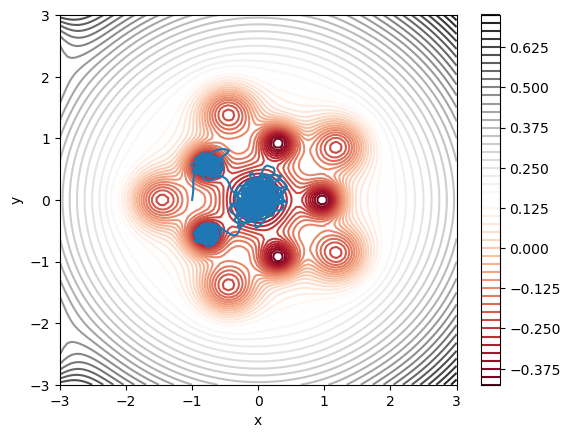

In [220]:
traj = read('md.traj@:')
print(len(traj))
#print(traj)
#print()
# Define an array to store the temperature at each step
temperatures = np.zeros(N_steps+1)

x = np.zeros(N_steps+1)
y = np.zeros(N_steps+1)
z = np.zeros(N_steps+1)

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    x[i] = xyz[0][0]
    y[i] = xyz[0][1]
    z[i] = xyz[0][2]
    
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()


plot_2d_bias(f_cvs,trajectory=[x,y],rangeCV1=[-3,3],rangeCV2=[-3,3])

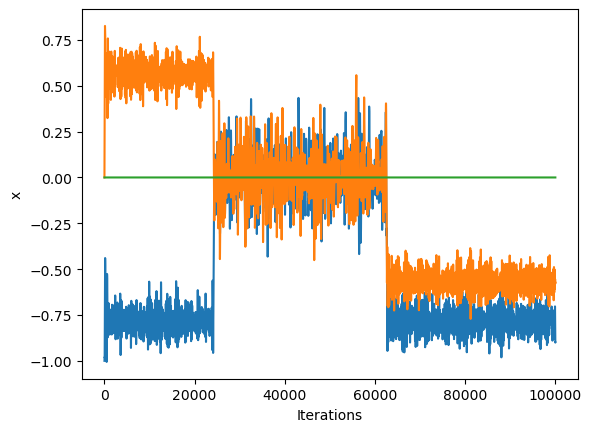

In [221]:
plt.plot(x)
plt.plot(y)
plt.plot(z)
plt.xlabel('Iterations')
plt.ylabel('x')
plt.savefig('Coordinates_2D_plot.png')

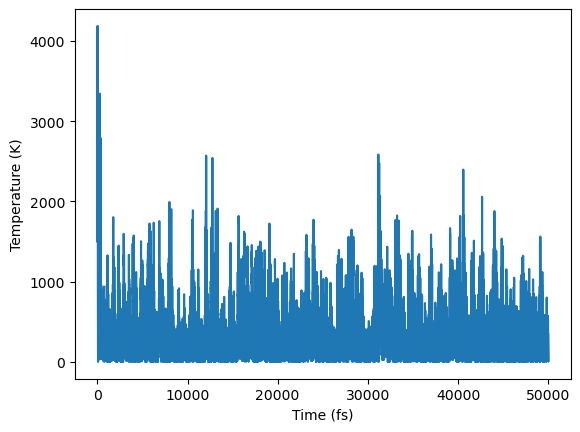

335.7314973649722


In [222]:
# Plot the temperature as a function of time
timestep = .5*units.fs
time_ = np.arange(N_steps+1) * timestep / units.fs
plt.plot(time_, temperatures)#/ units.kB)
plt.xlabel('Time (fs)')
plt.ylabel('Temperature (K)')
plt.savefig('NVT_DW_temp.png')
plt.show()
print(np.average(np.array(temperatures)))

## Now we try the Metadynamics code with this

[[-0.00404551  0.01201169  0.        ]]
Initial Array: None (1, 3)
[[-1.000069e+00  5.752047e-04]]
100001


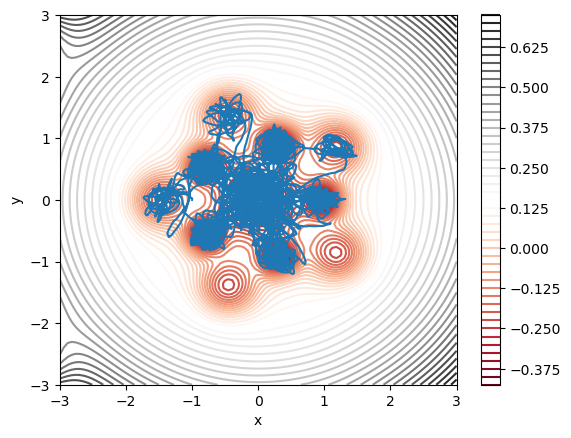

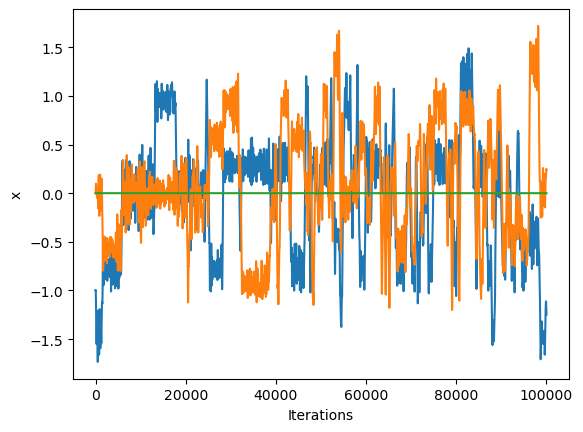

In [206]:
atoms = Atoms('C',[[-1.0,0.0,0.0]])

jax_calc = General_Bias_Calculator(_cvs_2D,f_cvs)
atoms.calc = jax_calc 


c = FixedPlane(
    [0],
    [0, 0, 1],
)

atoms.set_constraint(c)


MaxwellBoltzmannDistribution(atoms, temperature_K=600)
''' the first calc is thrash then but the second one looks great???
Stationary(atoms)  # zero linear momentum
ZeroRotation(atoms)  # zero angular momentum'''
print(atoms.get_velocities())
dyn = Metadynamics(atoms, timestep=.5 * units.fs, temperature_K=300, friction=.1, trajectory='md.traj',fixcm=False,cvs=_cvs_2D,interval_size=10)#Andersen(atoms, timestep=.5 * units.fs, temperature_K=3000, andersen_prob=0.01,trajectory='md.traj')#

#dyn = VelocityVerlet(atoms, timestep=1.0 * units.fs, trajectory='md.traj')

N_steps = int(1e5)
dyn.run(N_steps) 

traj = read('md.traj@::1')
print(len(traj))

#print(traj)
#print()
x = []
y = np.zeros(N_steps+1)
z = np.zeros(N_steps+1)

# Define an array to store the temperature at each step
temperatures = np.zeros(N_steps+1)
# Define an array to store the energy at each step
energy = np.zeros(N_steps+1)
kin = np.zeros(N_steps+1)
pot = np.zeros(N_steps+1)

for i,snap in enumerate(traj):
    xyz = snap.get_positions()
    x.append(xyz[0][0])
    y[i] = xyz[0][1]
    z[i] = xyz[0][2]
    
    # Record the temperature at this step
    temperatures[i] = snap.get_temperature()
    '''pot[i] = snap.get_potential_energy()
    kin[i] = snap.get_kinetic_energy()
    energy[i] =snap.get_total_energy()'''
    
    

plot_2d_bias(f_cvs,trajectory=[x,y],rangeCV1=[-3,3],rangeCV2=[-3,3])

plt.xlabel('Iterations')
plt.ylabel('x')
plt.plot(x)
plt.plot(y)
plt.plot(z)
#plt.savefig('X_movement_DW_C.png')

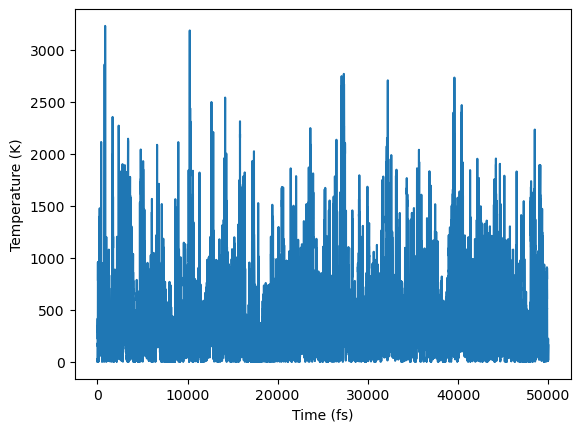

454.38486856515703


In [207]:
# Plot the temperature as a function of time
timestep = .5*units.fs
time_ = np.arange(N_steps+1) * timestep / units.fs
plt.plot(time_, temperatures)#/ units.kB)
plt.xlabel('Time (fs)')
plt.ylabel('Temperature (K)')
plt.savefig('NVT_DW_temp.png')
plt.show()
print(np.average(np.array(temperatures)))

(100, 100) (100, 100) 100


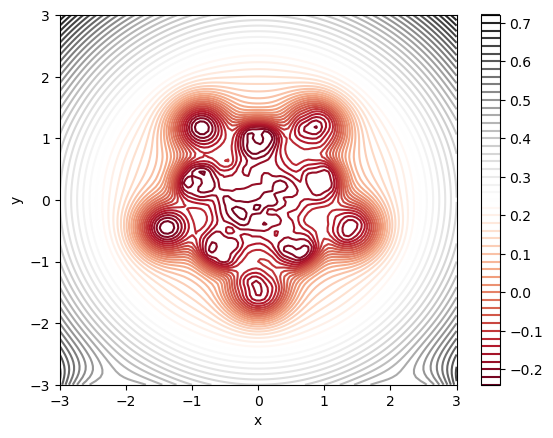

In [212]:
# Here now the biased potential should be plotted

atoms = Atoms('C',[[0.0,0.0,0.0]])



Z=[]
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x, y)
CVs=[X,Y]
for i in x:
    for j in y:
        atoms1=copy.deepcopy(atoms)
        pos = atoms.get_positions()
        pos[0][0]+=i
        pos[0][1]+=j
        atoms1.calc = dyn.return_biased_potential()
        atoms1.set_positions(pos)
         #needs to be an array for the spring method
        Z.append(atoms1.get_potential_energy())
Z=np.array(Z).reshape(100,100)
print(X.shape,Y.shape,len(Z))
plt.xlabel('x')
plt.ylabel('y')
plt.contour(X, Y, Z, 50, cmap='RdGy')
plt.colorbar()
plt.show()

(100, 100) (100, 100) 100


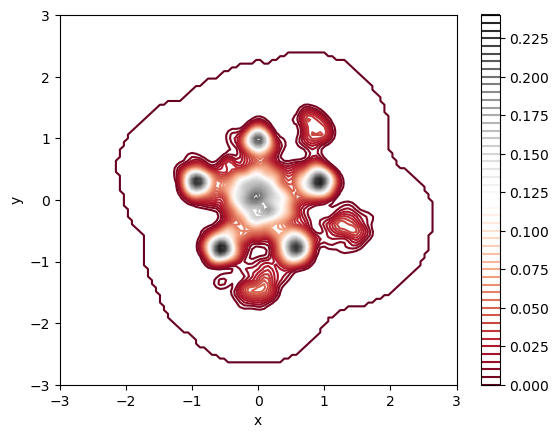

In [213]:
# Here now the biased potential should be plotted

atoms = Atoms('C',[[0.0,0.0,0.0]])



Z=[]
x = np.linspace(-3, 3, 100)
y = np.linspace(-3, 3, 100)
X, Y = np.meshgrid(x, y)
CVs=[X,Y]
for i in x:
    for j in y:
        atoms1=copy.deepcopy(atoms)
        pos = atoms.get_positions()
        pos[0][0]+=i
        pos[0][1]+=j
        atoms1.calc = dyn.return_bias()
        atoms1.set_positions(pos)
         #needs to be an array for the spring method
        Z.append(atoms1.get_potential_energy())
Z=np.array(Z).reshape(100,100)
print(X.shape,Y.shape,len(Z))
plt.xlabel('x')
plt.ylabel('y')
plt.contour(X, Y, Z, 50, cmap='RdGy')
plt.colorbar()
plt.show()

In [226]:
from ase.build import fcc100, add_adsorbate
from ase.optimize import FIRE,BFGS
from ase.calculators.lammpsrun import LAMMPS
from ase.constraints import FixAtoms

In [265]:
def _distance(atom_pos):
    return jnp.array([jnp.sqrt(sum((atom_pos[75]-atom_pos[76])**2))])

In [295]:
initial = fcc100('Pd', size=(5, 5, 3), vacuum=10.0)
dimer = fcc100('Pd', size=(2, 1, 1), vacuum=10.0)
add_adsorbate(initial, dimer, 1.611, position=(4,4))
files = ['Pd_u3.eam']
lammps = LAMMPS(files=files)
lammps.set(pair_style='eam',pair_coeff=['* * Pd_u3.eam'],atom_style='charge',units='metal')
mask = [atom.tag > 2 for atom in initial]
constraint = FixAtoms(mask=mask)
initial.set_constraint(constraint)
initial.calc = lammps

In [298]:
FIRE(initial,trajectory='testing.traj').run(fmax=0.05)


      Step     Time          Energy         fmax
*Force-consistent energies used in optimization.
FIRE:    0 16:25:37     -265.856647*       1.3194
FIRE:    1 16:25:37     -266.097598*       1.1955
FIRE:    2 16:25:37     -266.491181*       0.9684
FIRE:    3 16:25:37     -266.904117*       0.7115
FIRE:    4 16:25:37     -267.220355*       0.6357
FIRE:    5 16:25:37     -267.393572*       0.5394
FIRE:    6 16:25:37     -267.462645*       0.6101
FIRE:    7 16:25:37     -267.499402*       0.6351
FIRE:    8 16:25:37     -267.512767*       0.6206
FIRE:    9 16:25:37     -267.538067*       0.5923
FIRE:   10 16:25:37     -267.572631*       0.5512
FIRE:   11 16:25:37     -267.612904*       0.4989
FIRE:   12 16:25:37     -267.654903*       0.4373
FIRE:   13 16:25:37     -267.694732*       0.3685
FIRE:   14 16:25:37     -267.729121*       0.2949
FIRE:   15 16:25:37     -267.758237*       0.2345
FIRE:   16 16:25:37     -267.778606*       0.1922
FIRE:   17 16:25:37     -267.789523*       0.1831
FI

True

In [297]:
%%time
MaxwellBoltzmannDistribution(initial, temperature_K=600)
#print(initial.get_velocities())

dyn = Langevin(initial, timestep=0.5 * units.fs, temperature_K=300, friction=.1,trajectory='md.traj',fixcm=False)


N_steps = int(1e3)
dyn.run(N_steps) 

CPU times: user 2.51 s, sys: 125 ms, total: 2.63 s
Wall time: 3.52 s


True

In [299]:
%%time
MaxwellBoltzmannDistribution(initial, temperature_K=600)
#print(initial.get_velocities())

dyn = Metadynamics(initial, timestep=.5 * units.fs, temperature_K=300, friction=.1, trajectory='metad.traj',fixcm=False,cvs=_distance,interval_size=10,std_dev=1,bias_height=.1)

N_steps = int(1e3)
dyn.run(N_steps) 

Initial Array: None (77, 3)
[[2.6179519]]
CPU times: user 9.47 s, sys: 333 ms, total: 9.8 s
Wall time: 10.4 s


True

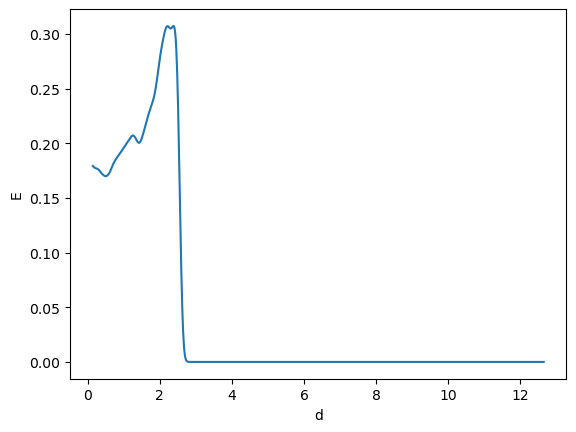

In [301]:
# Here now the biased potential should be plotted

initial.calc=None


Z=[]
x = np.linspace(-2.5, 10, 1000)

for i in x:
    atoms1=copy.deepcopy(initial)
    pos = initial.get_positions()
    pos[76][0]+=i
    atoms1.calc = dyn.return_bias()
    atoms1.set_positions(pos)
     #needs to be an array for the spring method
    Z.append(atoms1.get_potential_energy())
plt.plot((x +2.6472), Z)
plt.xlabel('d')
plt.ylabel('E')
#plt.savefig('.png')
plt.show()